# ONS daily peak demand: EDA, 7-day XGBoost and 2027 forecast (CSV ingestion)

This notebook reads the **CSV** files published by ONS. Its twin, `01_parquet.ipynb`, reads the Parquet files.
Only the ingestion SQL (`sql/00_raw_csv.sql`) differs. Staging, features and models live in `sql/` and `src/pipeline.py` and are shared.

**Target:** `val_demandainstantanea`, the daily maximum instantaneous demand per subsystem (MW).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pipeline as p

FORMAT = "csv"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
SUBS = ["SE", "S", "NE", "N"]
NAMES = {"SE": "Southeast/Midwest", "S": "South", "NE": "Northeast", "N": "North"}

## 1. Ingestion

The raw view, as the file delivers it, before any typing:

In [2]:
print((ROOT / "sql" / "00_raw_csv.sql").read_text())
con, ingest_s = p.connect(FORMAT)
files = sorted((ROOT / "data" / "raw").glob("*.csv"))
size_kb = sum(f.stat().st_size for f in files) / 1024
print(f"{len(files)} files, {size_kb:,.0f} KB on disk, ingestion {ingest_s*1000:,.0f} ms")
con.sql("DESCRIBE raw_demanda_maxima").df()[["column_name", "column_type"]]

-- Ingestion, CSV variant. Everything arrives as text; typing happens in staging.
CREATE OR REPLACE VIEW raw_demanda_maxima AS
SELECT *
FROM read_csv('data/raw/DEMANDA_MAXIMA_DI_*.csv', delim = ';', header = true, all_varchar = true);



3 files, 358 KB on disk, ingestion 1,008 ms


,column_name,column_type
0,id_subsistema,VARCHAR
1,nom_subsistema,VARCHAR
2,dat_referencia,VARCHAR
3,din_demandaintegralizada,VARCHAR
4,val_demandaintegralizada,VARCHAR
5,din_demandainstantanea,VARCHAR
6,val_demandainstantanea,VARCHAR


## 2. Staging and data quality (SQL)

In [3]:
con.sql("SELECT * FROM stg_demanda_maxima ORDER BY din_instante, id_subsistema LIMIT 8").df()

,din_instante,id_subsistema,nom_subsistema,demanda_maxima_mw,demanda_integralizada_mwmed,din_pico
0,2024-01-01,N,NORTE,7565.803,7689.391,2024-01-01 23:24:00
1,2024-01-01,NE,NORDESTE,13317.053,13215.209,2024-01-01 22:15:00
2,2024-01-01,S,SUL,13252.582,13157.030,2024-01-01 21:12:00
3,2024-01-01,SE,SUDESTE,41626.180,41545.438,2024-01-01 21:00:00
4,2024-01-02,N,NORTE,7678.973,7772.551,2024-01-02 22:52:00
5,2024-01-02,NE,NORDESTE,14253.710,14147.204,2024-01-02 21:55:00
6,2024-01-02,S,SUL,14986.845,14796.228,2024-01-02 11:28:00
7,2024-01-02,SE,SUDESTE,47556.297,47466.482,2024-01-02 20:46:00


In [4]:
con.sql('''
SELECT id_subsistema,
       COUNT(*)                                   AS days,
       MIN(din_instante)                          AS first_day,
       MAX(din_instante)                          AS last_day,
       COUNT(*) FILTER (demanda_maxima_mw IS NULL) AS missing_days,
       ROUND(MIN(demanda_maxima_mw))              AS min_mw,
       ROUND(AVG(demanda_maxima_mw))              AS mean_mw,
       ROUND(MAX(demanda_maxima_mw))              AS max_mw
FROM fct_demanda_diaria
GROUP BY 1 ORDER BY mean_mw DESC
''').df()

,id_subsistema,days,first_day,last_day,missing_days,min_mw,mean_mw,max_mw
0,SE,1049,2024-01-01,2026-11-14,0,41626.0,52144.0,62456.0
1,S,1049,2024-01-01,2026-11-14,0,12792.0,16968.0,22979.0
2,NE,1049,2024-01-01,2026-11-14,0,12654.0,15137.0,18423.0
3,N,1049,2024-01-01,2026-11-14,0,7171.0,9029.0,11400.0


In [5]:
dupes = con.sql("SELECT din_instante, id_subsistema, COUNT(*) n FROM stg_demanda_maxima GROUP BY 1, 2 HAVING n > 1").df()
inst_lt_int = con.sql("SELECT COUNT(*) AS n FROM stg_demanda_maxima WHERE demanda_maxima_mw < demanda_integralizada_mwmed").df().n[0]
print("duplicate (day, subsystem) rows:", len(dupes))
print("days where instantaneous peak < integrated value:", inst_lt_int)

duplicate (day, subsystem) rows: 0
days where instantaneous peak < integrated value: 727


## 3. Exploratory analysis

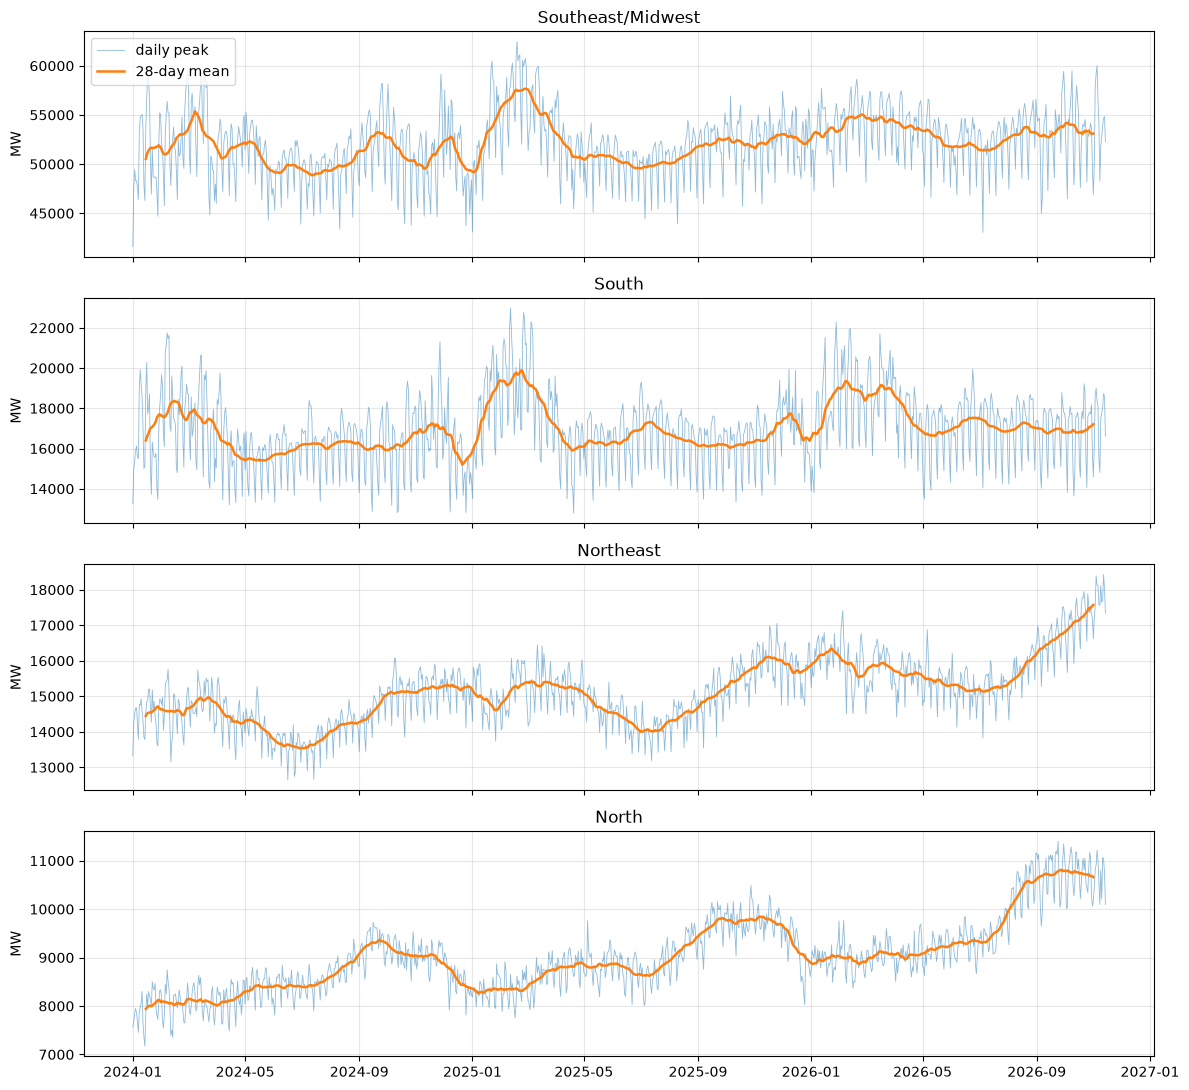

In [6]:
df = con.sql("SELECT * FROM fct_demanda_diaria").df()
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, s in zip(axes, SUBS):
    g = df[df.id_subsistema == s].sort_values("din_instante")
    ax.plot(g.din_instante, g.demanda_maxima_mw, lw=0.6, alpha=0.5, label="daily peak")
    ax.plot(g.din_instante, g.demanda_maxima_mw.rolling(28, center=True).mean(), lw=1.8, label="28-day mean")
    ax.set_title(NAMES[s]); ax.set_ylabel("MW")
axes[0].legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "01_daily_peak.png", dpi=120); plt.show()

Southeast/Midwest is about 3x any other subsystem, so errors are compared with **WAPE** and relative skill, not absolute MW.
Summer (Jan to Mar) peaks are clear in SE and S, driven by air conditioning. North and Northeast grow fastest (5 to 8% a year); SE grows about 2%.

In [7]:
annual = con.sql('''
SELECT id_subsistema, YEAR(din_instante) AS year, ROUND(AVG(demanda_maxima_mw)) AS mean_peak_mw
FROM fct_demanda_diaria
WHERE MONTH(din_instante) <= 10          -- Jan-Oct only: 2026 is incomplete
GROUP BY 1, 2 ORDER BY 1, 2
''').df().pivot(index="id_subsistema", columns="year", values="mean_peak_mw")
annual["growth_25_vs_24"] = annual[2025] / annual[2024] - 1
annual["growth_26_vs_25"] = annual[2026] / annual[2025] - 1
annual.style.format({2024: "{:,.0f}", 2025: "{:,.0f}", 2026: "{:,.0f}", "growth_25_vs_24": "{:+.1%}", "growth_26_vs_25": "{:+.1%}"})

year,2024,2025,2026,growth_25_vs_24,growth_26_vs_25
id_subsistema,,,,,
N,"8,471","8,909","9,595",+5.2%,+7.7%
NE,"14,372","14,874","15,877",+3.5%,+6.7%
S,"16,440","17,064","17,520",+3.8%,+2.7%
SE,"51,167","52,210","53,194",+2.0%,+1.9%


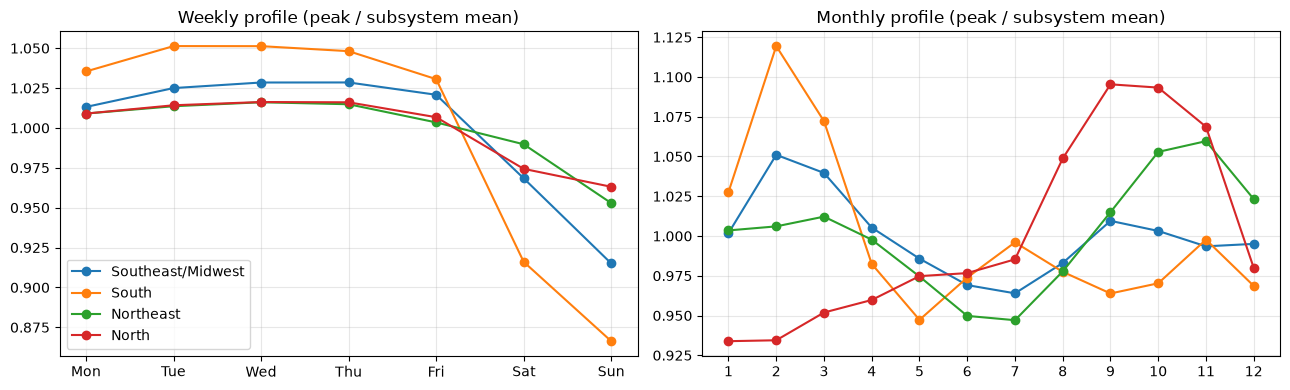

In [8]:
feat = con.sql("SELECT * FROM fct_demanda_features").df()
feat["norm"] = feat.demanda_maxima_mw / feat.groupby("id_subsistema").demanda_maxima_mw.transform("mean")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for s in SUBS:
    g = feat[feat.id_subsistema == s]
    a1.plot(days, g.groupby("dia_semana").norm.mean(), marker="o", label=NAMES[s])
    a2.plot(range(1, 13), g.groupby("mes").norm.mean(), marker="o", label=NAMES[s])
a1.set_title("Weekly profile (peak / subsystem mean)"); a2.set_title("Monthly profile (peak / subsystem mean)")
a2.set_xticks(range(1, 13)); a1.legend()
fig.tight_layout(); fig.savefig(FIG / "02_weekly_monthly_profile.png", dpi=120); plt.show()

Sundays sit 11% (SE) to 18% (S) below midweek; in N and NE only about 5%. The weekly cycle is the reason seasonal naive (same weekday last week) is the right floor.

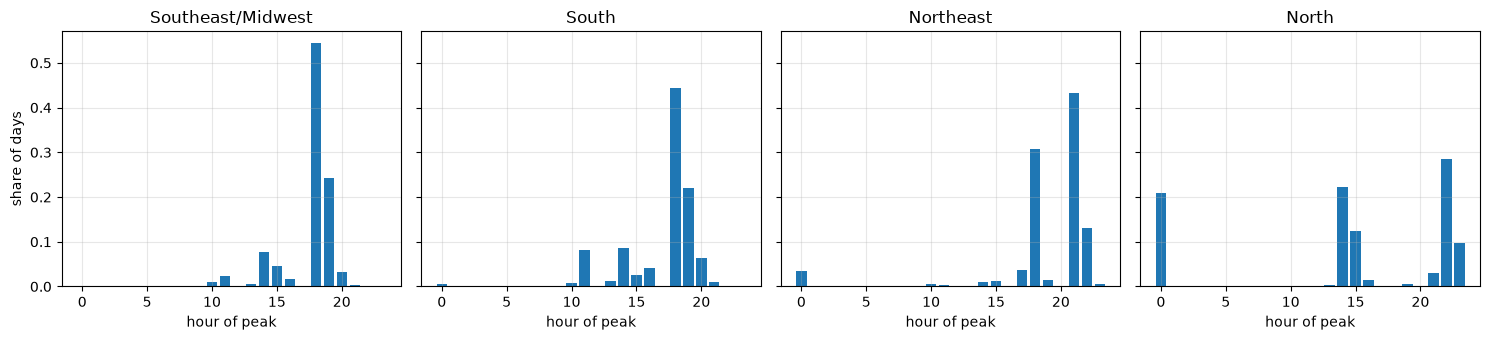

In [9]:
hours = df.assign(hour=df.din_pico.dt.hour)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, s in zip(axes, SUBS):
    h = hours[hours.id_subsistema == s].groupby("hour").size().reindex(range(24), fill_value=0)
    ax.bar(h.index, h / h.sum()); ax.set_title(NAMES[s]); ax.set_xlabel("hour of peak")
axes[0].set_ylabel("share of days")
fig.tight_layout(); fig.savefig(FIG / "03_peak_hour.png", dpi=120); plt.show()

SE and S peak mostly at 18h to 19h, NE at 21h, and N is split between late night and early afternoon.
Few afternoon peaks in SE and S is consistent with behind-the-meter solar (MMGD) shaving the midday load: the system peak arrives as solar output fades.

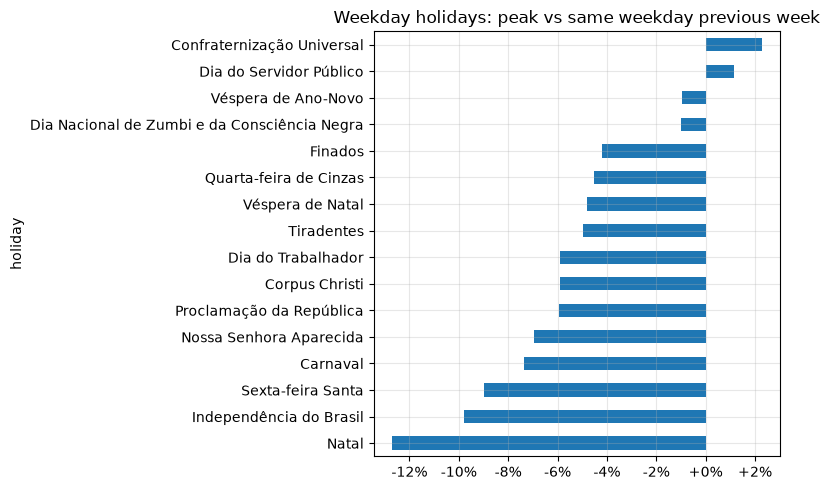

In [10]:
hol = con.sql('''
SELECT f.nome AS holiday, s.id_subsistema,
       s.demanda_maxima_mw / s.lag_7d - 1 AS vs_same_weekday_last_week
FROM fct_demanda_features s JOIN feriados f ON f.data = s.din_instante
WHERE s.lag_7d IS NOT NULL AND s.dia_semana <= 5
''').df()
(hol.groupby("holiday").vs_same_weekday_last_week.mean().sort_values()
    .plot.barh(figsize=(8, 5), title="Weekday holidays: peak vs same weekday previous week"))
plt.gca().xaxis.set_major_formatter(lambda x, _: f"{x:+.0%}")
plt.tight_layout(); plt.savefig(FIG / "04_holiday_effect.png", dpi=120); plt.show()

Weekday holidays cut the peak by up to 13% (Christmas); Independence Day, Good Friday and Carnival by 7 to 10%. This is why `feriado` is a feature and not left to the model to guess.

## 4. 7-day-ahead model: XGBoost vs seasonal naive

Features come from `sql/04_fct_demanda_features.sql`. All of them are at least 7 days old, so nothing from the forecast week leaks in.
Validation is walk-forward with an expanding window. The holdout (2026-08-15 to 2026-11-14) is used once, below.

In [11]:
print((ROOT / "sql" / "04_fct_demanda_features.sql").read_text())

-- Features for a 7-day-ahead forecast. Every window is strictly backward-looking AND at least
-- 7 days old: on the forecast day only data up to t-7 is known, so lag_1d would be leakage here.
CREATE OR REPLACE VIEW fct_demanda_features AS
SELECT
    f.din_instante,
    f.id_subsistema,
    CASE f.id_subsistema WHEN 'SE' THEN 0 WHEN 'S' THEN 1 WHEN 'NE' THEN 2 WHEN 'N' THEN 3 END AS cod_subsistema,
    f.demanda_maxima_mw,

    LAG(f.demanda_maxima_mw, 7)   OVER w AS lag_7d,     -- also the seasonal naive forecast
    LAG(f.demanda_maxima_mw, 14)  OVER w AS lag_14d,
    LAG(f.demanda_maxima_mw, 364) OVER w AS lag_52w,

    AVG(f.demanda_maxima_mw) OVER (
        PARTITION BY f.id_subsistema
        ORDER BY f.din_instante
        ROWS BETWEEN 13 PRECEDING AND 7 PRECEDING
    ) AS media_movel_7d,                                -- last fully known week

    c.dia_semana,
    c.mes,
    c.dia_ano,
    c.feriado
FROM fct_demanda_diaria f
JOIN dim_calendario c USING (din_instante)
WINDOW w 

In [12]:
cv = p.walk_forward(feat)
cv.pivot(index="test", columns="model", values="WAPE").style.format("{:.2%}")

model,last_week_mean,seasonal_naive,xgboost
test,,,
2025-07-01 → 2025-09-30,4.10%,2.31%,2.33%
2025-10-01 → 2025-12-31,4.08%,3.71%,3.36%
2026-01-01 → 2026-03-31,4.85%,4.37%,3.99%
2026-04-01 → 2026-06-30,4.13%,3.31%,2.82%
2026-07-01 → 2026-08-14,4.23%,2.57%,2.52%


In [13]:
cv.groupby("model")[["WAPE", "MAPE", "skill_vs_naive"]].mean().style.format("{:.2%}")

,WAPE,MAPE,skill_vs_naive
model,,,
last_week_mean,4.28%,4.37%,-37.59%
seasonal_naive,3.25%,3.32%,0.00%
xgboost,3.00%,3.05%,6.83%


### Holdout (touched once)

In [14]:
ho = p.holdout(feat)
models = ["seasonal_naive", "last_week_mean", "xgboost"]
display(p.scores(ho, models).style.format("{:.2%}"))
pd.concat({NAMES[s]: p.scores(g, models)["WAPE"] for s, g in ho.groupby("id_subsistema")}, axis=1).T.style.format("{:.2%}")

,WAPE,MAPE,skill_vs_naive
seasonal_naive,3.78%,3.23%,0.00%
last_week_mean,4.78%,4.73%,-26.62%
xgboost,3.44%,3.53%,8.92%


,seasonal_naive,last_week_mean,xgboost
North,2.42%,3.57%,3.78%
Northeast,1.96%,2.78%,4.27%
South,3.91%,7.34%,3.04%
Southeast/Midwest,4.58%,4.84%,3.24%


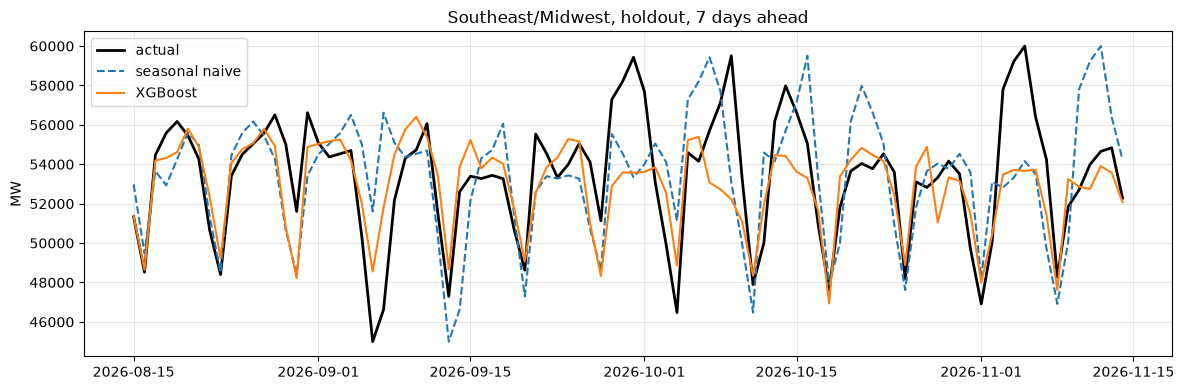

In [15]:
g = ho[ho.id_subsistema == "SE"]
plt.plot(g.din_instante, g.demanda_maxima_mw, "k", lw=2, label="actual")
plt.plot(g.din_instante, g.seasonal_naive, "--", label="seasonal naive")
plt.plot(g.din_instante, g.xgboost, label="XGBoost")
plt.title("Southeast/Midwest, holdout, 7 days ahead"); plt.ylabel("MW"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "05_holdout_se.png", dpi=120); plt.show()

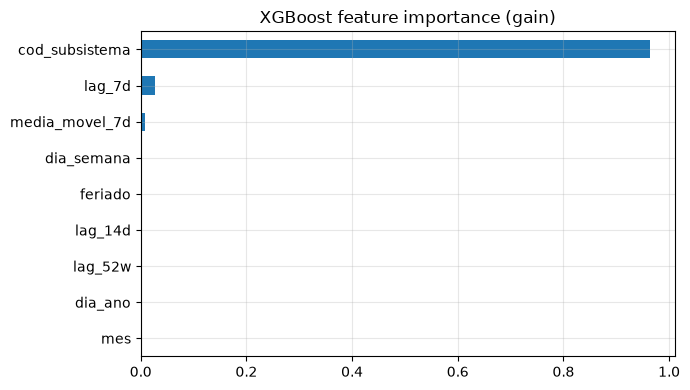

In [16]:
from xgboost import XGBRegressor
train = p.add_baselines(feat.dropna(subset=["lag_7d", "media_movel_7d"]))
m = XGBRegressor(**p.XGB_PARAMS).fit(train[p.FEATURES_7D], train.demanda_maxima_mw)
pd.Series(m.feature_importances_, p.FEATURES_7D).sort_values().plot.barh(figsize=(7, 4), title="XGBoost feature importance (gain)")
plt.tight_layout(); plt.savefig(FIG / "06_feature_importance.png", dpi=120); plt.show()

## 5. 2027 forecast (long horizon)

Lag features don't exist a year ahead, so this is a different model: a **linear trend per subsystem x an XGBoost seasonal ratio** using calendar features only (subsystem, weekday, month, day of year, holiday).
XGBoost alone cannot extrapolate growth, because trees predict inside the range they were trained on. The trend carries the growth.

First, a backtest of the method: train up to 2025-11-14, forecast the next 365 days, and compare with the annual naive (same weekday, 52 weeks earlier).

In [17]:
tr = feat[feat.din_instante < "2025-11-15"]
te = feat[feat.din_instante >= "2025-11-15"].copy()
te["annual_model"] = p.AnnualModel().fit(tr).predict(te)
te["seasonal_naive"] = te["lag_52w"]
display(p.scores(te, ["seasonal_naive", "annual_model"]).style.format("{:.2%}"))
pd.concat({NAMES[s]: p.scores(g, ["seasonal_naive", "annual_model"])["WAPE"] for s, g in te.groupby("id_subsistema")}, axis=1).T.style.format("{:.2%}")

,WAPE,MAPE,skill_vs_naive
seasonal_naive,5.52%,6.09%,0.00%
annual_model,4.17%,4.22%,24.51%


,seasonal_naive,annual_model
North,7.39%,3.41%
Northeast,6.40%,4.11%
South,6.28%,5.71%
Southeast/Midwest,4.67%,3.82%


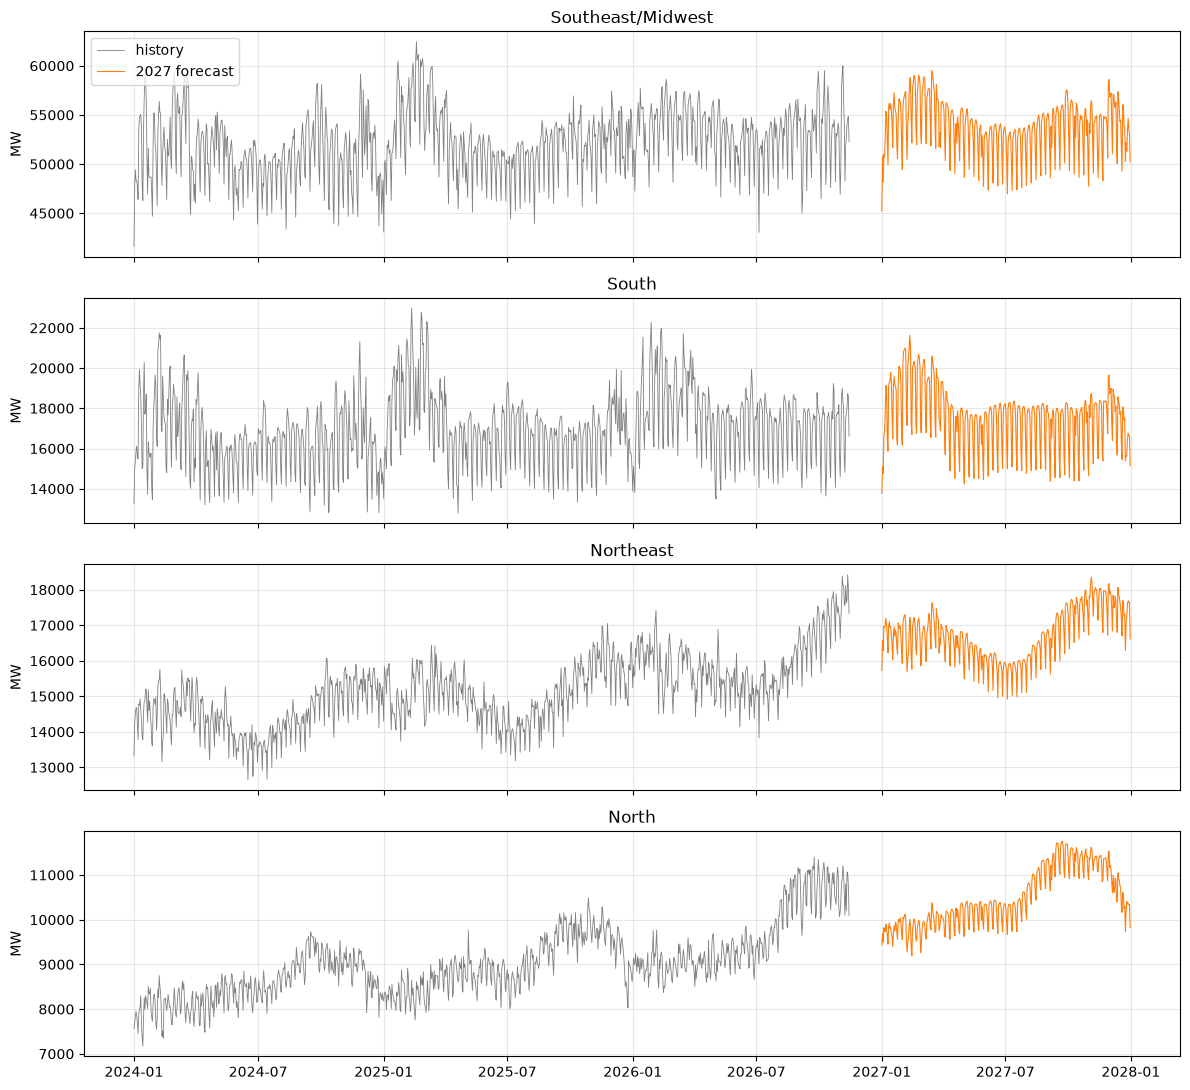

In [18]:
model = p.AnnualModel().fit(feat)
fc = p.calendar_2027(con)
fc["forecast_mw"] = model.predict(fc).round(1)
(ROOT / "outputs").mkdir(exist_ok=True)
fc[["din_instante", "id_subsistema", "nom_subsistema", "feriado", "forecast_mw"]].to_csv(ROOT / "outputs" / "forecast_2027.csv", index=False)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, s in zip(axes, SUBS):
    h = feat[feat.id_subsistema == s].sort_values("din_instante"); f = fc[fc.id_subsistema == s]
    ax.plot(h.din_instante, h.demanda_maxima_mw, lw=0.6, color="gray", label="history")
    ax.plot(f.din_instante, f.forecast_mw, lw=0.8, color="C1", label="2027 forecast")
    ax.set_title(NAMES[s]); ax.set_ylabel("MW")
axes[0].legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "07_forecast_2027.png", dpi=120); plt.show()

In [19]:
monthly = fc.groupby(["id_subsistema", "mes"]).forecast_mw.max().unstack(0)[SUBS].rename(columns=NAMES)
monthly.index.name = "2027 month"
monthly.style.format("{:,.0f}").set_caption("Forecast monthly maximum of daily peak, MW")

id_subsistema,Southeast/Midwest,South,Northeast,North
2027 month,,,,
1,"57,246","20,085","17,198","10,042"
2,"59,029","21,624","17,297","10,120"
3,"59,493","20,586","17,630","10,376"
4,"56,252","18,844","16,994","10,380"
5,"55,625","17,909","16,774","10,412"
6,"54,095","18,252","16,230","10,437"
7,"53,694","18,352","16,036","10,627"
8,"55,199","18,234","16,811","11,335"
9,"57,551","18,281","17,631","11,754"


## 6. Format note (CSV)

Size on disk and ingestion time for this format are printed in section 1. CSV arrives as text (all `VARCHAR`), so every date and number is cast in staging, and padded codes like `"N  "` need `TRIM`.
`python src/pipeline.py` asserts that both formats produce an identical feature table.